In [ ]:
config = {
    "prior":
        {
        "mu_loc": 0.0,
        "mu_scale": 0.2,
        "phi_alpha": 20.0,
        "phi_beta": 1.5,
        "sigma_ig_shape": 2.5,
        "sigma_ig_scale": 0.025,
        "m_loc": -1.5,
        "m_scale": 1.0,
        },
    "simulator":
        {
        "T": [200, 250],
        },
    "summary": 
        {
        "type": "lstm",
        "input_dim": 1,
        "hidden_dim": 4,
        "num_layers": 3,
        "output_dim": 10,
        "dropout": 0.1,
        },
    "logger":
        {
        "name": "StochVol",
        "level": "DEBUG",
        "log_file_path": "logs/stoch_vol.log",
        }
}
import os

if not os.path.exists("./logs"):
    os.mkdir("./logs")
if not os.path.exists("./models"):
    os.mkdir("./models")


In [2]:
import yaml
import torch
import time
import matplotlib.pyplot as plt


from sfmpe.tasks.StochVol import StochVolTask


device = 'cuda' if torch.cuda.is_available() else 'cpu'
task = StochVolTask(config, device)
theta_0 = task.prior.sample((1,))

Running 100 simulations.:   0%|          | 0/100 [00:00<?, ?it/s]

 Training neural network. Epochs trained: 11
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 11
        Best validation performance: -2.9022
        -------------------------
        


Drawing 100 posterior samples:   0%|          | 0/100 [00:00<?, ?it/s]

tensor([[-0.1624,  0.8976,  0.0868, -3.4531]])
tensor([[ 0.0130,  0.4169,  0.2311, -1.0369]])
tensor([[0.7510, 0.4475, 0.1584, 3.8697]])


Drawing 100 posterior samples:   0%|          | 0/100 [00:00<?, ?it/s]

...

Drawing 100 posterior samples:   0%|          | 0/100 [00:00<?, ?it/s]

Running 100 simulations.:   0%|          | 0/100 [00:00<?, ?it/s]

Using SNPE-C with atomic loss
 Training neural network. Epochs trained: 11
        -------------------------
        ||||| ROUND 3 STATS |||||:
        -------------------------
        Epochs trained: 11
        Best validation performance: -11.5110
        -------------------------
        


Drawing 100 posterior samples:   0%|          | 0/100 [00:00<?, ?it/s]

tensor([[-0.1624,  0.8976,  0.0868, -3.4531]])
tensor([[ 0.0720,  0.8777,  0.1509, -1.6839]])
tensor([[0.1479, 0.1086, 0.1203, 0.9581]])


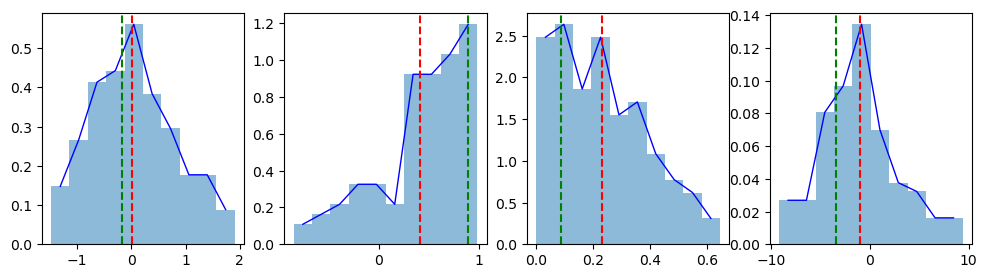

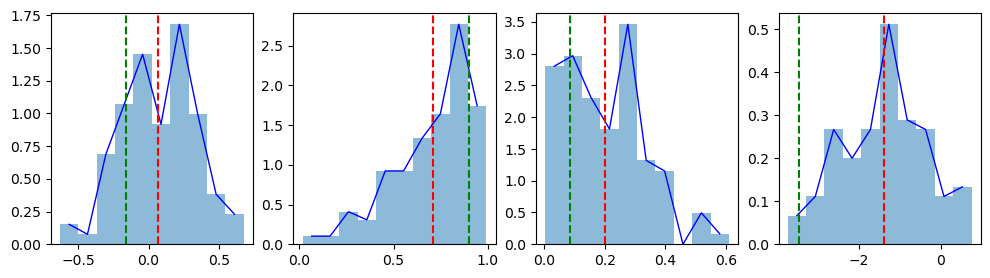

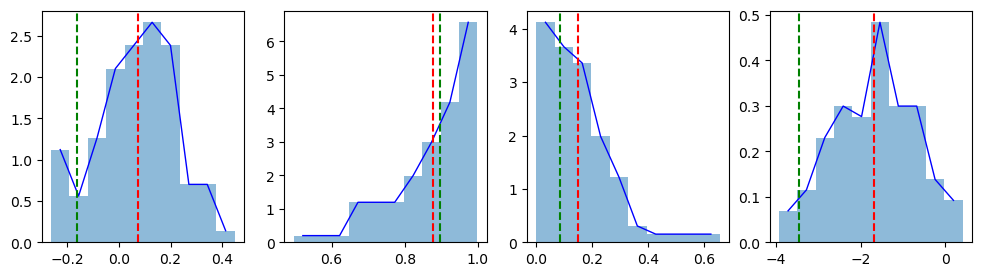

In [4]:
torch.autograd.set_detect_anomaly(True)
from torch.nn.utils.rnn import pack_padded_sequence
import torch.nn.functional as F

from sfmpe.utils.plotting import dist_plot
from sbi.inference import SNPE, simulate_for_sbi
from sbi.utils import posterior_nn
from sbi.utils.user_input_checks import process_prior, process_simulator


class PaddedLSTMSummary(torch.nn.Module):
    def __init__(self, summary):
        super().__init__()
        self.summary = summary
        self.input_dim = summary.input_dim
        self.output_dim = summary.output_dim

    def forward(self, data):
        if data.shape[-1] != self.input_dim + 1:
            raise ValueError("Expected observations plus one length-mask channel.")

        values = data[..., :self.input_dim]
        lengths = data[..., self.input_dim].sum(dim=-1).to(dtype=torch.long)
        batch_shape = values.shape[:-2]
        values = values.reshape(-1, values.shape[-2], self.input_dim)
        lengths = lengths.reshape(-1)
        packed = pack_padded_sequence(
            values, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.summary.lstm(packed)
        embedding = self.summary.fc(hidden[-1])
        return embedding.reshape(*batch_shape, self.output_dim)


prior, _, prior_returns_numpy = process_prior(task.prior)
configured_T = task.simulator.T
max_length = max(configured_T) if isinstance(configured_T, (tuple, list)) else int(configured_T)


def simulate_padded(theta):
    series = task.simulator.simulate(theta)
    sequence_length = series.shape[-2]
    if sequence_length > max_length:
        raise ValueError(f"Simulation length {sequence_length} exceeds {max_length}.")

    series = F.pad(series, (0, 0, 0, max_length - sequence_length))
    # Keep each original sequence length available to the packed LSTM embedding.
    mask = (torch.arange(max_length, device=series.device) < sequence_length).to(series.dtype)
    mask = mask.view(*([1] * (series.ndim - 2)), max_length, 1)
    mask = mask.expand(*series.shape[:-1], 1)
    return torch.cat((series, mask), dim=-1)


simulator = process_simulator(simulate_padded, task.prior, prior_returns_numpy)
x_0 = simulator(theta_0)

embedding_net = PaddedLSTMSummary(task.summary.to("cpu"))
density_estimator = posterior_nn(
    model="maf",
    embedding_net=embedding_net,
    z_score_x=None,
)
inference = SNPE(prior=task.prior, density_estimator=density_estimator)

num_rounds=3
num_samples=100
show_train_summary=True
max_num_epochs=10
stop_after_epochs=max_num_epochs


proposal = prior

for _ in range(num_rounds):
    theta, x = simulate_for_sbi(simulator, proposal=proposal, num_simulations=num_samples)

    # In `SNLE` and `SNRE`, you should not pass the `proposal` to `.append_simulations()`.
    density_estimator = inference.append_simulations(
        theta, x, proposal=proposal
    ).train(show_train_summary=show_train_summary, stop_after_epochs=stop_after_epochs, max_num_epochs=max_num_epochs)
    posterior = inference.build_posterior(density_estimator, sample_with="rejection")
    proposal = posterior.set_default_x(x_0)
    proposal_theta = proposal.sample((num_samples, )).unsqueeze(1)
    print(theta_0, proposal_theta.mean(dim=0), proposal_theta.std(dim=0), sep="\n")
    dist_plot(proposal_theta, pred_param=proposal_theta.mean(dim=0), true_param=theta_0)
